C:\Users\ch355\AppData\Local\Temp\ipykernel_28108\3237300805.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sido_sum, x='시도', y='물동량', palette='Blues_r', ax=ax)


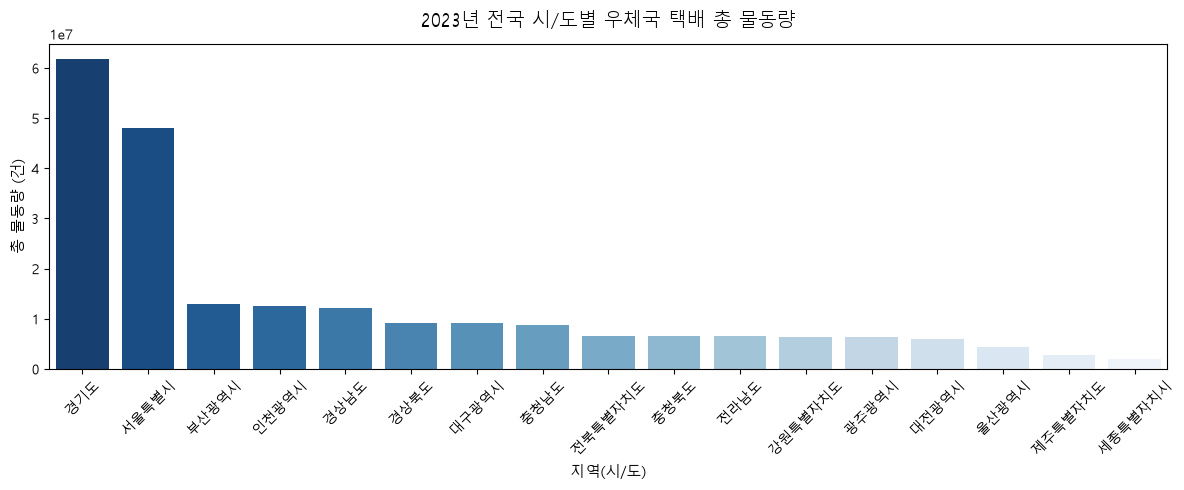

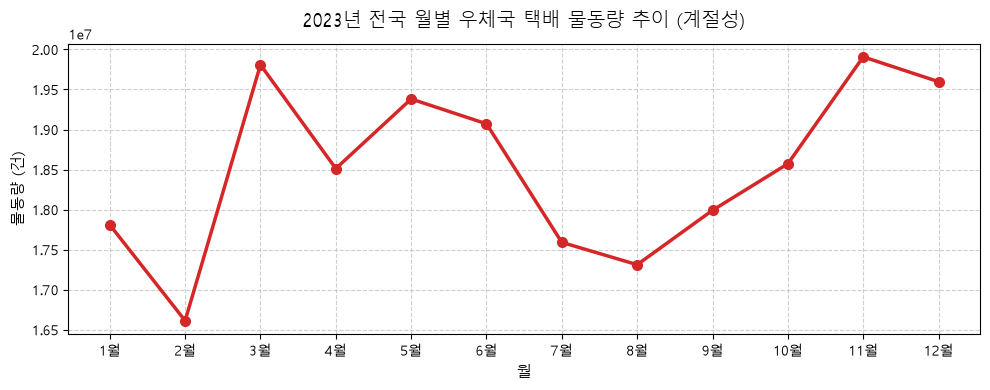

In [ ]:
import matplotlib as mpl
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

df_long = pd.read_csv('preprocessed_parcel_data.csv', encoding='utf-8')


plt.rc('font', family='Malgun Gothic') # Windows 기본 한글 폰트(맑은 고딕) 설정
plt.rcParams['axes.unicode_minus'] = False # 마이너스(-) 기호 깨짐 방지

# 1. 전국 17개 시/도별 연간 총 물동량 비교

sido_sum = (df_long.groupby('시도')['물동량'].sum().reset_index() .sort_values(by='물동량', ascending=False))

fig, ax = plt.subplots(figsize=(12, 5))

sns.barplot(data=sido_sum, x='시도', y='물동량', palette='Blues_r', ax=ax)

ax.set_title('2023년 전국 시/도별 우체국 택배 총 물동량', fontsize=14, pad=12)
ax.set_xlabel('지역(시/도)', fontsize=11)

ax.set_ylabel('총 물동량 (건)', fontsize=11)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('sido_total_bar.png', dpi=300, bbox_inches='tight')
plt.show()

# 2. 1월~12월 전국 월별 물동량 추이 (계절성 분석)

monthly_sum = ( df_long.groupby(['월 숫자', '월'])['물동량'].sum().reset_index().sort_values('월 숫자'))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly_sum['월'],monthly_sum['물동량'],marker='o',color='#d62728',linewidth=2.5,markersize=7,)
ax.set_title('2023년 전국 월별 우체국 택배 물동량 추이 (계절성)', fontsize=14, pad=12)

ax.set_xlabel('월', fontsize=11)
ax.set_ylabel('물동량 (건)', fontsize=11)
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('monthly_trend_line.png', dpi=300, bbox_inches='tight')
plt.show()